# Using Plot3D Interactive Field Plotting Tool

This tutorial details the usage of the `slabguide` package's 3D interactive plotting tool `Plot3D`.  It covers all controller options as well as keyboard bindings for interacting with the plot.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from slabguide import Slab, Propagator, real_contour, Plot3D

%matplotlib widget
plt.style.use('dark_background')

## Setting up

To use the tool, we need fields to visualize, and we get them by defining a slab waveguide using the `Slab` class, and input field, and propagating that input using an instance of `Propagator`.  The following cells perform this task for the default waveguide and standard input.  See notebook [1.1-Basic_3_Layer](1.1-Basic_3_Layer.ipynb).

In [2]:
A = Slab()

In [3]:
half_width = 0.6
shift = 0.35
amplitude = 1.0

Lx = -half_width + shift
Rx = half_width + shift

def quadratic_piecewise(x):
    x = np.array(x, dtype=float)
    conds = [(x < Lx), ((Lx <= x)*(x <= Rx)), (x > Rx)]
    funcs = [lambda x: 0, lambda x: amplitude * (1 - ((x - shift) / half_width)**2), lambda x: 0]
    return np.piecewise(x, conds, funcs)

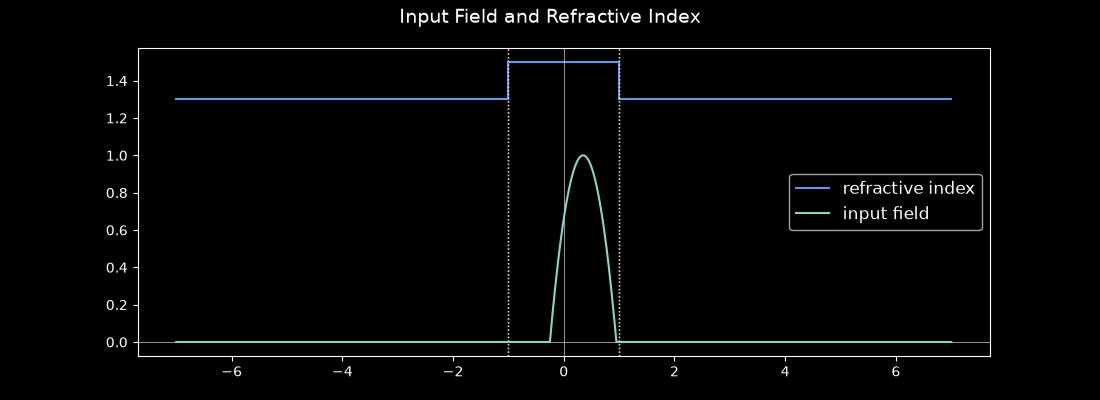

In [4]:
A.plot_refractive_index(part='real', label='refractive index', title="Input Field and Refractive Index");
A.add_1d_plot(quadratic_piecewise, label='input field');

In [5]:
P = Propagator(A, f0=quadratic_piecewise, window=[Lx,Rx])

In [6]:
P.add_contour(real_contour(.00001, A.Z_evanescent, 150))
P.add_contour(real_contour(A.Z_evanescent, 8*A.Z_evanescent, 200))

## Plotting the Induced Field

Initializing the plot is as simple as passing the `Propagator` instance to the plotter:

In [8]:
%env ANYWIDGET_HMR=1

env: ANYWIDGET_HMR=1


In [9]:
Plot3D(P);

<slabguide.plotting.Plot3D.Plot3D.<locals>.HelloWidget object at 0x7f2aedf9b590>

## Keyboard and Touchpad Interaction

Plot3D is driven by the JavaScript library ThreeJS, and uses OrbitControls to facilitate interaction.  According to the [documentation](https://threejs.org/docs/?q=orbit#OrbitControls):

> <p>Orbit controls allow the camera to orbit around a target. OrbitControls performs orbiting, dollying (zooming), and panning. Unlike TrackballControls it maintains the "up" direction <code>object.up</code> (+Y by default).</p>
> <ul>
> <li>Orbit: Left mouse / touch: one-finger move.</li>
> <li>Zoom: Middle mouse, or mousewheel / touch: two-finger spread or squish.</li>
> <li>Pan: Right mouse, or left mouse + ctrl/meta/shiftKey, or arrow keys / touch: two-finger move.</li>
> </ul>

In our case, we have set the controls to have the +Z axis correspond to the "up" direction, which allows for easy rotation of the plane of propagation.